## Exercice 3 : un CNN sur MNIST

Objectif : classer des images de chiffres manuscrits (0 à 9) avec un réseau convolutif. Le réseau compte 130890 paramètres, et la dernière couche convolutive sort 3 x 3 x 64 = 576 valeurs, que Flatten met a plat. La validation est prélevée dans le train, pour que le test reste inconnu jusqu'à l'évaluation finale.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


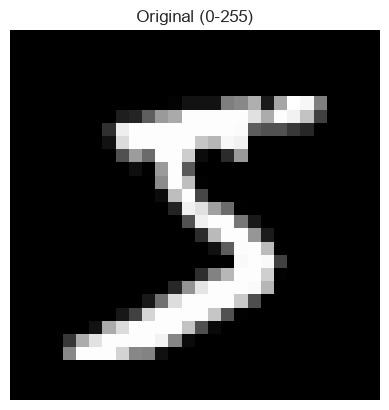

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9219 - loss: 0.2523 - val_accuracy: 0.9853 - val_loss: 0.0520
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9781 - loss: 0.0741 - val_accuracy: 0.9882 - val_loss: 0.0429
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9844 - loss: 0.0533 - val_accuracy: 0.9902 - val_loss: 0.0359
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9875 - loss: 0.0421 - val_accuracy: 0.9903 - val_loss: 0.0337
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9896 - loss: 0.0342 - val_accuracy: 0.9895 - val_loss: 0.0413
313/313 - 1s - 3ms/step - accuracy: 0.9913 - loss: 0.0295

Précision sur le test : 99.13%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


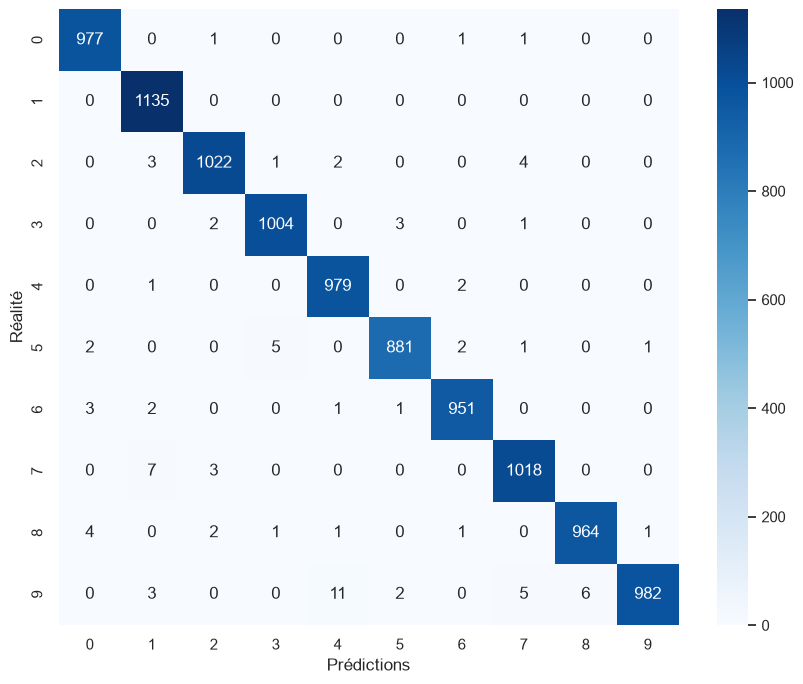

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.98      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       1.00      0.97      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



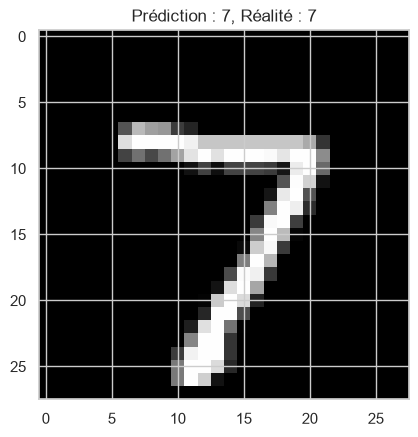

In [16]:
# ============================================================
# 1) IMPORTS — les boîtes à outils
# ============================================================
import numpy as np              # calcul sur des tableaux de nombres (une image = un tableau de pixels)
import matplotlib.pyplot as plt # afficher des images et des graphiques
import seaborn as sns           # de jolis graphiques (ici : la matrice de confusion)
from tensorflow.keras import datasets, layers, models, Input          # construire et entraîner le réseau
from sklearn.metrics import confusion_matrix, classification_report  # mesurer la qualité des prédictions

# ============================================================
# 2) CHARGEMENT — 70 000 chiffres manuscrits
# ============================================================
# MNIST : une base célèbre de chiffres écrits à la main, de 0 à 9.
# Chaque image : un carré de 28 x 28 = 784 pixels, en niveaux de gris.
# X = les images (les « questions »), y = les labels (les « réponses » : le chiffre dessiné)
# - X_train / y_train : 60 000 exemples, les « fiches de révision » pour apprendre
# - X_test / y_test   : 10 000 exemples pour l'examen final, jamais vus pendant l'apprentissage
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

# On jette un œil à une image brute, avant toute transformation :
# c'est un tableau numpy de 28 x 28, où chaque case (pixel) vaut 0 (noir) à 255 (blanc).
# Ici : la 1ère image du train dont la réponse est « 5 »
img = X_train[y_train ==5][0]
plt.imshow(img, cmap='gray')  # niveaux de gris
plt.title("Original (0-255)")
plt.axis("off")               # pas d'axes, pour une image propre
plt.show()

# ============================================================
# 3) PRÉPARATION — normalisation + format attendu par Keras
# ============================================================
# a) / 255 : les pixels passent de [0, 255] à [0, 1]
#    -> des petites valeurs homogènes aident le réseau à apprendre
# b) expand_dims(..., -1) : on ajoute une dimension « canaux » à la fin
#    Keras attend (hauteur, largeur, canaux) ; 1 canal = niveaux de gris (3 = couleur RVB)
#    Donc (N, 28, 28) -> (N, 28, 28, 1)
X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)
print("Formes finales :", X_train.shape, X_test.shape)

# ============================================================
# 4) LE RÉSEAU — un empilement de couches, chacune affine l'image
# ============================================================
# Principe général : les premières couches repèrent des motifs tout simples,
# les suivantes les combinent en motifs de plus en plus riches, jusqu'à
# reconnaître des morceaux de chiffres, puis des chiffres entiers.
model = models.Sequential([  # les couches s'enchaînent une après l'autre
    Input(shape=(28, 28, 1)),  # entrée : une image 28x28 pixels, 1 canal

    # Conv2D : 32 petits détecteurs de motifs, chacun une fenêtre de 3x3 pixels.
    # Chaque détecteur glisse sur toute l'image ; à chaque position il compare
    # la fenêtre à son motif et donne un score -> on obtient 32 « cartes de motifs »
    # qui indiquent où chaque motif a été trouvé.
    # 1er étage -> motifs simples : bords, traits, coins.
    # relu : garde les scores positifs, remplace les négatifs par 0.
    layers.Conv2D(32, (3, 3), activation='relu'),

    # MaxPooling : découpe l'image en zones 2x2 et ne garde que le pixel le plus fort
    # de chaque zone -> image 2x plus petite. Bonus : si un motif bouge d'un pixel,
    # il reste détecté — un « résumé » robuste aux petits décalages.
    layers.MaxPooling2D((2, 2)),

    # 2e étage : 64 détecteurs, qui regardent les cartes du 1er étage
    # et combinent les motifs simples -> boucles, intersections...
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # 3e étage : encore 64 détecteurs, pour des motifs encore plus abstraits
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten : on aplatit la pile de cartes de motifs (3x3x64 = 576 nombres)
    # en une seule longue liste, pour pouvoir l'offrir aux couches Dense.
    layers.Flatten(),

    # Dense(128) : 128 neurones « classiques » — chacun regarde TOUS les motifs
    # détectés et calcule une somme pondérée, pour apprendre quelles combinaisons
    # de motifs caractérisent chaque chiffre.
    layers.Dense(128, activation='relu'),

    # Dropout : pendant l'entraînement, on coupe au hasard la moitié des
    # connexions -> le réseau ne peut pas « réciter par cœur » un seul chemin,
    # il apprend des indices redondants et solides.
    layers.Dropout(0.5),

    # Sortie : 10 neurones, un par chiffre possible (0 à 9).
    # softmax transforme leurs scores en probabilités qui totalisent 100 %
    # (ex. « 5 » à 92 %, « 3 » à 6 %, le reste se partage les miettes)
    layers.Dense(10, activation="softmax"),
])

# ============================================================
# 5) COMPILATION — la méthode d'apprentissage
# ============================================================
# Avant d'apprendre, Keras veut savoir 3 choses :
# optimizer="adam" : la recette qui corrige les poids. À chaque paquet d'images,
#   le réseau mesure son erreur, et adam ajuste tous les poids dans le sens
#   qui la réduit — petit pas après petit pas.
# loss="sparse_categorical_crossentropy" : la « note » d'erreur à faire baisser.
#   « sparse » : les réponses sont des numéros simples (ex. 5), pas des listes
#   de dix 0/1. Plus le loss est petit, plus les prédictions collent aux réponses.
# metrics=["accuracy"] : le % de bonnes réponses, affiché à chaque tour —
#   le critère qu'un humain comprend le plus facilement.
model.compile(optimizer="adam", 
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()  # récapitulatif des couches et du nombre de paramètres (poids) appris

# ============================================================
# 6) ENTRAÎNEMENT — le réseau apprend de ses erreurs
# ============================================================
# epochs=5 : on repasse 5 fois sur tout le train
# batch_size=64 : les images sont montrées par paquets de 64
# validation_split=0.1 : 10 % du train mis de côté pour vérifier, à chaque tour,
#                        que le réseau généralise — le test reste inconnu jusqu'à la fin
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

# ============================================================
# 7) EXAMEN FINAL — sur des images jamais vues
# ============================================================
# evaluate() fait prédire le réseau sur les 10 000 images du test,
# puis compare ses prédictions aux vraies réponses :
# - loss : la même « note » d'erreur que pendant l'entraînement, mais sur le test
# - acc  : le % de chiffres correctement reconnus
# C'est LE chiffre qui compte : il mesure la capacité à généraliser,
# pas à répéter ce qu'on lui a montré.
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2f}%")

# ============================================================
# 8) ANALYSE DES ERREURS
# ============================================================
# predict -> 10 probabilités par image ; argmax garde la plus grande = chiffre prédit
y_pred = np.argmax(model.predict(X_test), axis=-1)

# Matrice de confusion : ligne = vrai chiffre, colonne = chiffre prédit.
# La diagonale = les bonnes réponses ; le reste = les confusions (ex. 4 vs 9)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel("Réalité")
plt.show()

# Rapport détaillé, chiffre par chiffre :
#   precision : parmi mes prédictions de ce chiffre, combien sont justes ?
#   recall    : parmi les vrais exemples de ce chiffre, combien ai-je trouvés ?
print(classification_report(y_test, y_pred))

# Un dernier exemple : une image du test, sa prédiction vs la réalité
# (squeeze : enlève la dimension canal pour pouvoir réafficher l'image)
plt.imshow(X_test[0].squeeze(), cmap='gray')
plt.title(f"Prédiction : {y_pred[0]}, Réalité : {y_test[0]}")
plt.show()


## Slide présentation CNN

https://docs.google.com/presentation/d/144AZJt97pBBoE85QpGiKDjoPmSPxxWLmDfEmODbr69A